# LAB: Python for Data Analysis - Exploratory Data Analysis (EDA)

## Introduction

Welcome to the Exploratory Data Analysis (EDA) lab! As a junior data analyst at a retail company, your task is to explore and analyze a sales dataset to uncover valuable insights that can influence business decisions.

You will work with a dataset that includes various numerical and categorical variables related to sales transactions. Your goal is to perform a thorough exploratory analysis to identify trends, anomalies, and opportunities.

## Initial setup

### Fork and Clone the Repository

Start by forking the provided GitHub repository to your account and then clone it locally. This will be your workspace for completing the lab exercises.

### Scenario

Imagine you are a junior data analyst at a retail company. Your manager has asked you to perform an exploratory analysis of sales data to uncover actionable insights. Your task is to explore and analyze this dataset to identify trends, anomalies, and potential opportunities for the company. You will be working with a dataset that includes various numerical and categorical variables related to sales transactions. Your goal is to perform a thorough exploratory analysis to uncover valuable insights that can influence business decisions.

## Iteration 1: Load and Inspect the Dataset

### Import the necessary libraries

In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


### Load the dataset

In [101]:
df = pd.read_csv('sales_data.csv', encoding = 'UTF-8')

### Inspect the dataset

In [103]:
df.info

<bound method DataFrame.info of            Date Product_ID         Category Region  Sales  Discount
0    2023-10-22      P7094      Electronics   West  122.0      0.05
1    2023-05-07      P2495  Health & Beauty  North  455.0      0.19
2    2023-04-02      P6426           Sports   West  368.0       NaN
3    2023-01-25      P9218         Clothing   East  290.0      0.33
4    2023-11-03      P7915  Health & Beauty   East  126.0      0.30
..          ...        ...              ...    ...    ...       ...
153  2023-05-23      P9113    Home & Garden   West  227.0      0.44
154  2023-10-27      P7151         Clothing  South    NaN      0.24
155  2023-12-25      P9559           Sports  South  450.0       NaN
156  2023-02-23      P5366         Clothing   West  220.0      0.45
157  2023-08-21      P3293         Clothing  North  329.0      0.40

[158 rows x 6 columns]>

In [105]:
df.describe()

,Sales,Discount
count,141.000000,142.000000
mean,270.716312,0.256056
std,135.748945,0.138794
min,21.000000,0.000000
25%,158.000000,0.132500
50%,280.000000,0.250000
75%,383.000000,0.360000
max,495.000000,0.500000


In [107]:
df.shape

(158, 6)

In [109]:
df.columns

Index(['Date', 'Product_ID', 'Category', 'Region', 'Sales', 'Discount'], dtype='object')

In [111]:
df.dtypes

Date           object
Product_ID     object
Category       object
Region         object
Sales         float64
Discount      float64
dtype: object

## Iteration 2: Data Cleaning

### Correct data types

In [115]:

dtype_df = {
    'Date': 'datetime64[ns]',
    'Product_ID': str,
    'Category': 'category',
    'Region': 'category',
    'Sales': float,
    'Discount': float,
}

print(df.dtypes)
print('-' * 100)
df = df.astype(dtype_df)
print(df.dtypes)


Date           object
Product_ID     object
Category       object
Region         object
Sales         float64
Discount      float64
dtype: object
----------------------------------------------------------------------------------------------------
Date          datetime64[ns]
Product_ID            object
Category            category
Region              category
Sales                float64
Discount             float64
dtype: object


### Handle missing values

In [79]:
df.isnull().sum()

Date            0
Product_ID      0
Category        0
Region          0
Sales         158
Discount        0
dtype: int64

In [161]:
# otra manera de hacer es darle mean a Sales dependiendo de su categoria
# df['Sales'] = df['Sales'].fillna(df.groupby('Category')['Sales'].transform('mean'))

In [119]:
df['Sales'] = df['Sales'].fillna(df['Sales'].mean())

In [123]:
df['Discount'] = df['Discount'].fillna(df['Discount'].mean())

In [127]:
df.head(10)

,Date,Product_ID,Category,Region,Sales,Discount
0,2023-10-22,P7094,Electronics,West,122.000000,0.050000
1,2023-05-07,P2495,Health & Beauty,North,455.000000,0.190000
2,2023-04-02,P6426,Sports,West,368.000000,0.256056
3,2023-01-25,P9218,Clothing,East,290.000000,0.330000
4,2023-11-03,P7915,Health & Beauty,East,126.000000,0.300000
5,2023-05-04,P7823,Clothing,North,91.000000,0.140000
6,2023-08-17,P4422,Sports,North,208.000000,0.280000
7,2023-12-09,P8497,Home & Garden,East,40.000000,0.190000
8,2023-12-27,P2054,Home & Garden,South,122.000000,0.490000
9,2023-02-02,P1036,Electronics,East,270.716312,0.420000


### Remove duplicates

In [139]:
df.duplicated().sum()

8

In [141]:
duplicados_exactos = df[df.duplicated(keep=False)]  # `keep=False` marca todos los duplicados

# Mostrar ejemplos (como el que compartiste)
print(duplicados_exactos.sort_values(by='Date'))


          Date Product_ID       Category Region       Sales  Discount
42  2023-01-03      P4266  Home & Garden  South  207.000000  0.320000
152 2023-01-03      P4266  Home & Garden  South  207.000000  0.320000
41  2023-01-05      P3954         Sports   East  495.000000  0.140000
150 2023-01-05      P3954         Sports   East  495.000000  0.140000
146 2023-02-23      P5366       Clothing   West  220.000000  0.450000
156 2023-02-23      P5366       Clothing   West  220.000000  0.450000
110 2023-05-23      P9113  Home & Garden   West  227.000000  0.440000
153 2023-05-23      P9113  Home & Garden   West  227.000000  0.440000
90  2023-08-21      P3293       Clothing  North  329.000000  0.400000
157 2023-08-21      P3293       Clothing  North  329.000000  0.400000
128 2023-10-27      P7151       Clothing  South  270.716312  0.240000
154 2023-10-27      P7151       Clothing  South  270.716312  0.240000
109 2023-12-18      P8079    Electronics  North  270.716312  0.280000
151 2023-12-18      

In [157]:
# keep='first': Conserva la primera aparición (usa 'last' para la última).
df = df.drop_duplicates(subset=['Date', 'Product_ID'], keep='first')

## Iteration 3: Data Visualization with Matplotlib and Seaborn

In [ ]:
# me exporto la base de datos limpio
df.to_csv('df_limpio.csv', index=False)


In [175]:
df.describe()

,Date,Sales,Discount
count,150,150.000000,150.000000
mean,2023-07-15 04:28:48,268.691631,0.252872
min,2023-01-01 00:00:00,21.000000,0.000000
25%,2023-04-04 06:00:00,172.250000,0.140000
50%,2023-08-01 12:00:00,270.716312,0.256056
75%,2023-10-20 06:00:00,367.000000,0.350000
max,2023-12-30 00:00:00,495.000000,0.500000
std,NaN,129.139847,0.132202


### Distribution of Numerical Variables

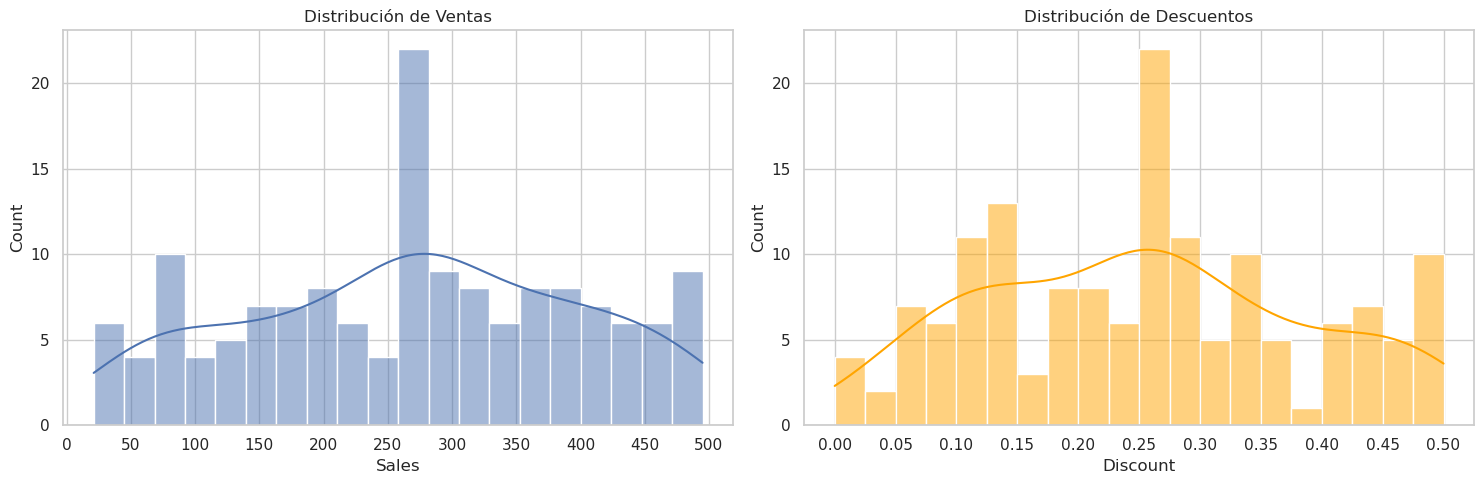

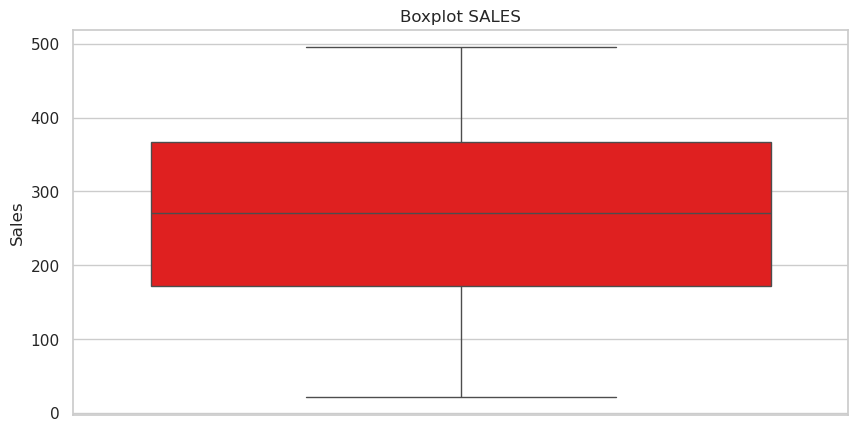

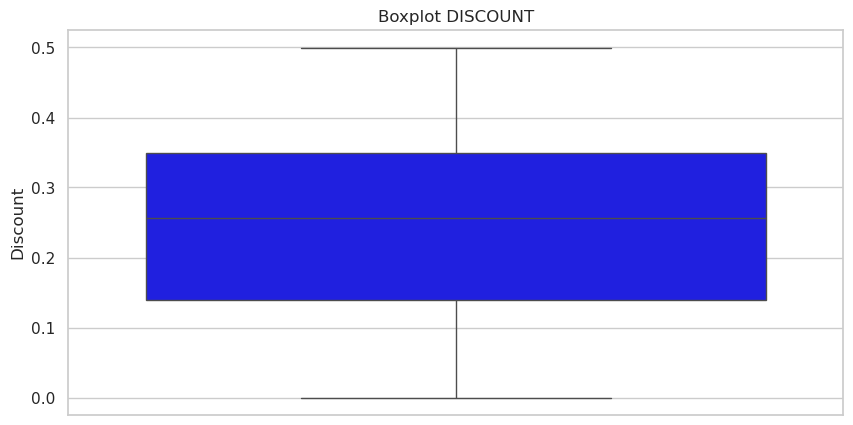

In [219]:
# Histogramas con más valores en eje X
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma para 'Sales'
sns.histplot(data=df, x='Sales', kde=True, bins=20, ax=axes[0])
axes[0].set_title('Distribución de Ventas')
axes[0].set_xticks(range(0, int(df['Sales'].max()) + 50, 50))  # Mostrar valores cada 50 unidades

# Histograma para 'Discount'
sns.histplot(data=df, x='Discount', bins=20, ax=axes[1], color='orange', kde = True)
axes[1].set_title('Distribución de Descuentos')
axes[1].set_xticks([i/20 for i in range(0, 11)])  # Mostrar valores mas separados

# aqui las dos graficas separdas de Boxplot
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))
sns.boxplot(data=df['Sales'], color = 'red')
plt.title('Boxplot SALES')
plt.show()

plt.figure(figsize=(10, 5))
sns.boxplot(data=df['Discount'], color = 'blue')
plt.title('Boxplot DISCOUNT')
plt.show()

### Categorical Variable Analysis

/tmp/ipykernel_14092/3322676561.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette="viridis",  alpha=0.7,  edgecolor='black')
/tmp/ipykernel_14092/3322676561.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Region', order=df['Region'].value_counts().index,


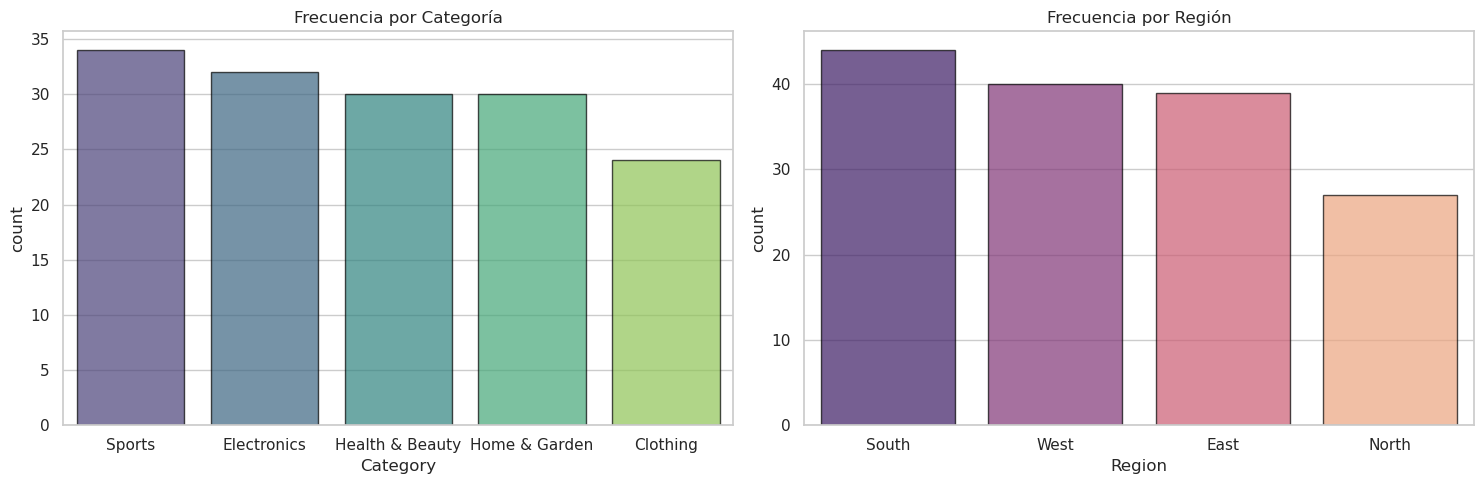

In [245]:

# Frecuencia de categorías
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette="viridis",  alpha=0.7,  edgecolor='black')
plt.title('Frecuencia por Categoría')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Region', order=df['Region'].value_counts().index,
    palette="magma",    # Otra paleta de colores
    alpha=0.7,          # Misma transparencia
    edgecolor='black')
plt.title('Frecuencia por Región')
plt.tight_layout()
plt.show()

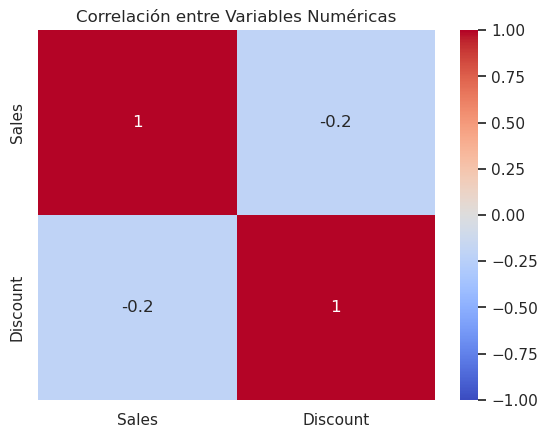

In [235]:
# Heatmap de correlación
corr = df[['Sales', 'Discount']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmax = 1, vmin = -1)
plt.title('Correlación entre Variables Numéricas')
plt.show()

### Sales Trends Over Time

/tmp/ipykernel_14092/436208925.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  .resample('M').sum()\


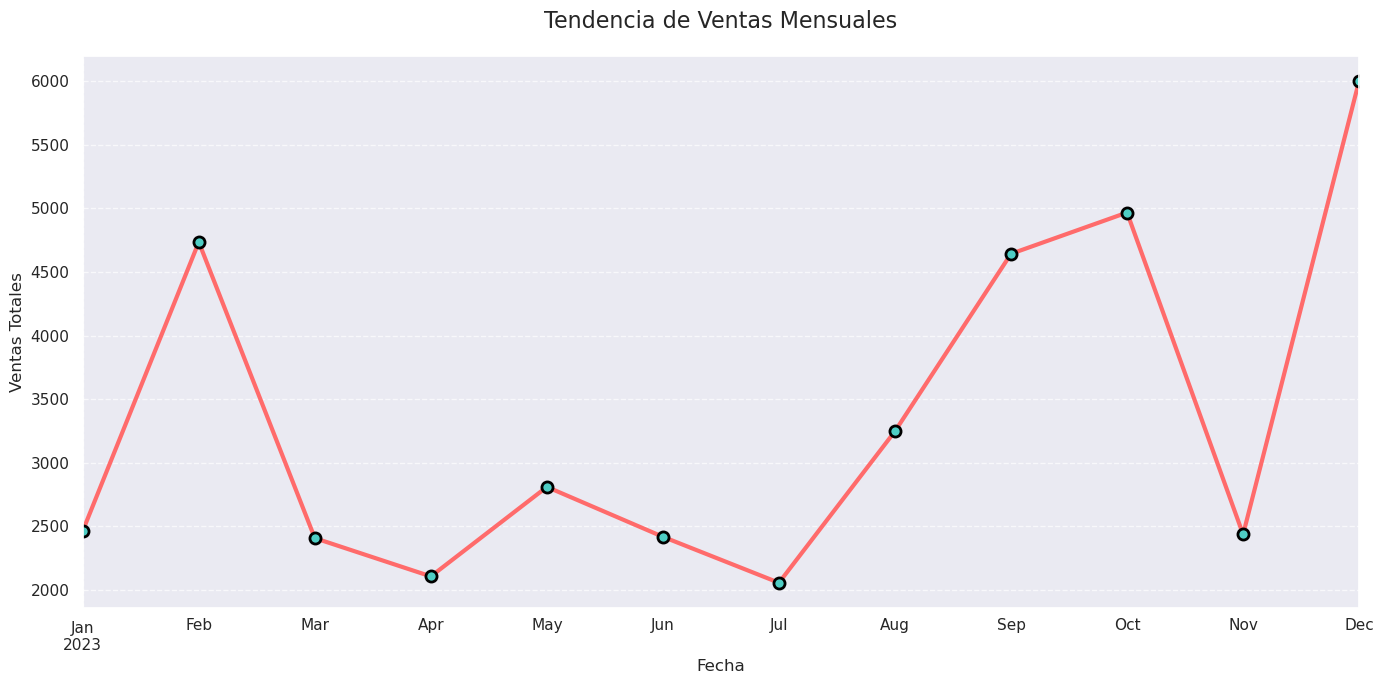

In [259]:

# Configuración de estilo
plt.figure(figsize=(14, 7))
sns.set_style("darkgrid")  # Fondo con grid oscuro


# Resample de ventas por mes y gráfico de línea
df.set_index('Date')['Sales']\
    .resample('M').sum()\
    .plot(color='#FF6B6B',  # Color coral
          linewidth=3,     # Grosor de línea
          marker='o',      # Marcadores en cada punto
          markersize=8,
          markerfacecolor='#4ECDC4',  # Color turquesa para marcadores
          markeredgewidth=2,
          markeredgecolor='black')

# Personalización
plt.title('Tendencia de Ventas Mensuales', fontsize=16, pad=20)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Ventas Totales', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)  # Grid punteado


plt.tight_layout()
plt.show()

### Sales by Category and Region

<Figure size 1600x1200 with 0 Axes>

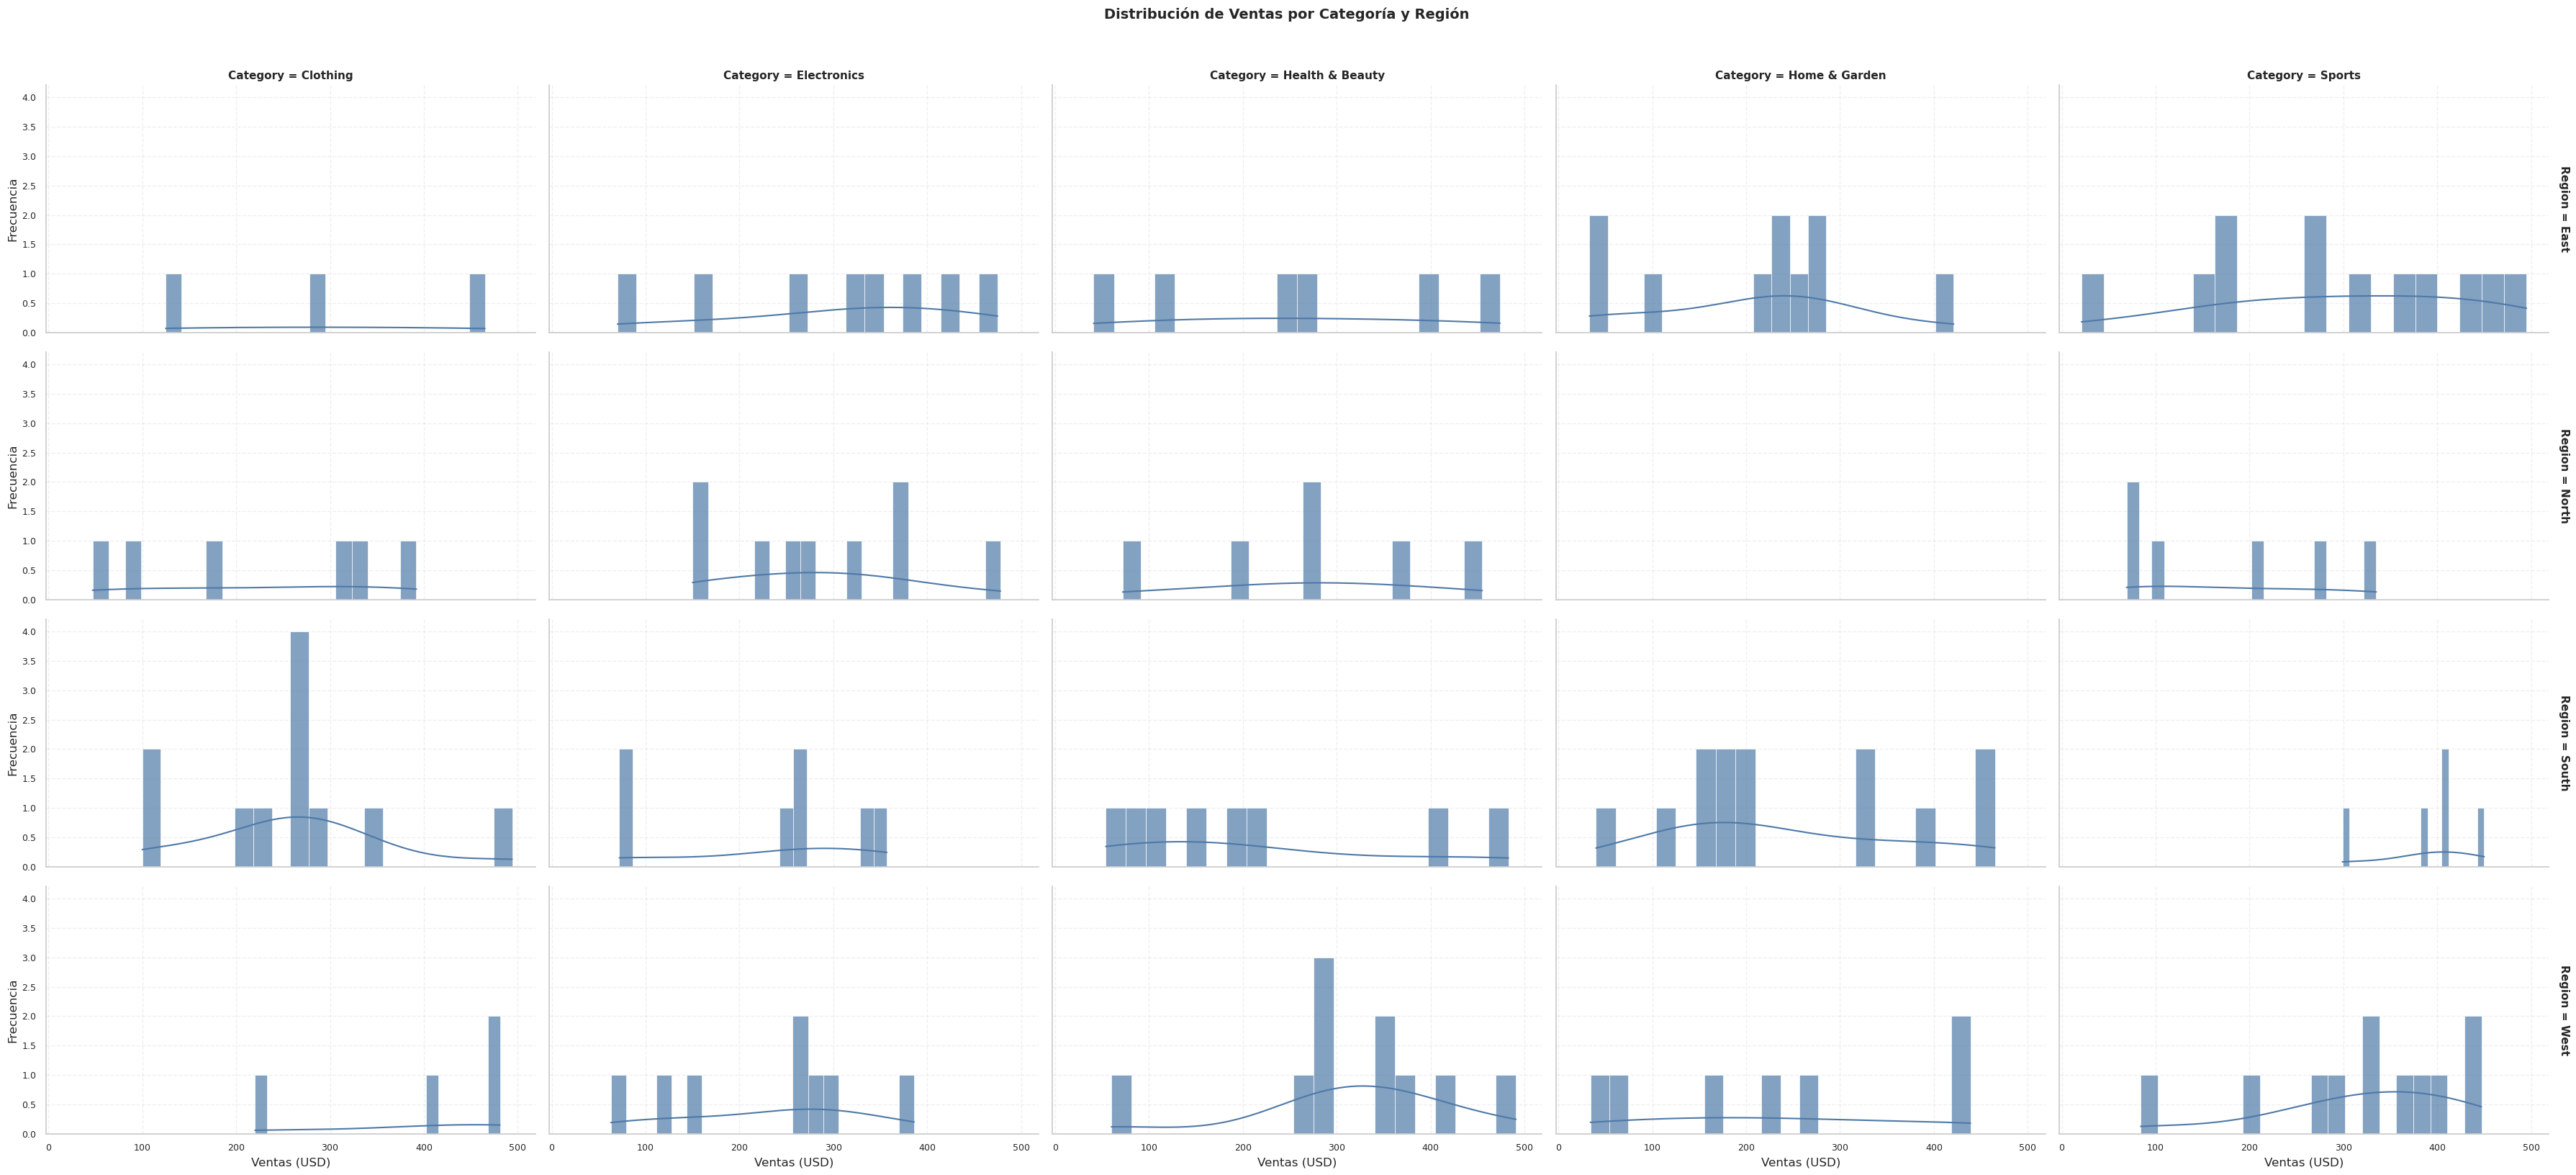

In [281]:

# Configuración del estilo
sns.set_style("whitegrid")
plt.figure(figsize=(16, 12))  # Tamaño más grande

# Crear FacetGrid mejorado
g = sns.FacetGrid(
    data=df,
    col='Category',
    row='Region',
    height=4,          # Aumentar altura de cada subgráfico
    aspect=1.8,        # Proporción más ancha
    margin_titles=True, # Títulos más claros
    palette='viridis'   # Esquema de color consistente
)

# Mapear histogramas con mejoras visuales
g.map(
    sns.histplot,
    'Sales',
    bins=20,           # Más bins para mayor detalle
    kde=True,          # Añadir línea de densidad
    color='#4e79a7',   # Color azul profesional
    alpha=0.7,         # Transparencia
    edgecolor='white',  # Borde blanco para las barras
    linewidth=0.5       # Grosor del borde
)

# Personalizar títulos y ejes
g.set_titles('{row_name} | {col_name}', size=11, weight='bold')
g.set_axis_labels('Ventas (USD)', 'Frecuencia')
g.fig.suptitle('Distribución de Ventas por Categoría y Región', y=1.02, size=14, weight='bold')

# Ajustar espacio entre subplots
plt.tight_layout()

# Mejorar los ejes y ticks
for ax in g.axes.flat:
    ax.tick_params(axis='both', which='major', labelsize=9)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.show()

### Pair Plot Analysis

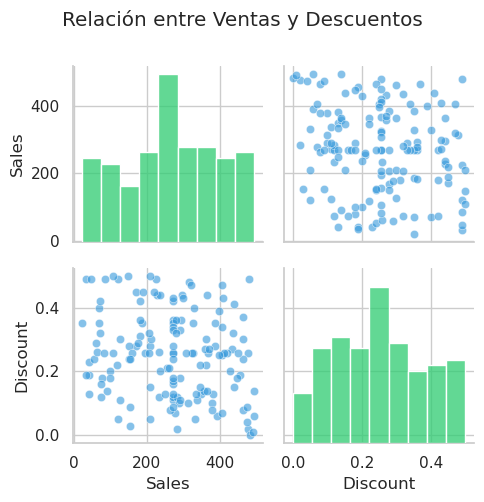

In [278]:
# Pair Plot simplificado
sns.pairplot(
    data=df[['Sales', 'Discount']], hue = '
    kind='scatter',  # Solo gráfico de dispersión
    plot_kws={
        'alpha': 0.6,
        'color': '#3498db'  # Azul sencillo
    },
    diag_kws={
        'color': '#2ecc71'  # Verde para histogramas
    }
)

# Título y ajustes
plt.suptitle('Relación entre Ventas y Descuentos', y=1)
plt.tight_layout()
plt.show()

## Iteration 5: Data Scaling

### 1. Select the Numerical Variables:

### 2. Standardize the Variables:

### 3. Verify the Transformation:

## Iteration 6: Hypothesis Testing

### 1. Formulate the Hypotheses:

### 2. Perform the Normality Test:

### 3. Select the Appropriate Hypothesis Test:

### 4. Interpret the Results:

## Iteration 7: Dimensionality Reduction with PCA

### 1. Prepare the Data:

### 2. Apply PCA:

### 3. Analyze Results:

### 4. Visualize PCA Components:

### 5. Explore Component Loadings:

## Iteration 8: Summarize Findings

### Create a Report

## Summarize Findings